# GNSS pod oblohou: skutečné družice, DOP, terén a výška v Bpv

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/gnss_sky_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [GNSS pod oblohou](https://openskylab.space/edu_viz_gnss_sky.html) · [English version](gnss_sky_en.ipynb)

Vizuál ukazuje, jak počet a rozložení družic určují DOP, co udělají překážky a elevační maska a proč je výška z GNSS méně přesná než poloha. Tady spočítáš polohy skutečných družic GPS, Galileo, GLONASS a BeiDou z vysílaných efemerid, skutečný horizont v údolí Vltavy z modelu terénu ČÚZK a převod elipsoidické výšky na výšku v Bpv z bodů bodového pole.

**Cíl:** nakreslit skutečnou oblohu GNSS nad Suchdolem, spočítat HDOP, VDOP a PDOP během dne, posoudit vliv lesa a hlubokého údolí, najít nejbližší referenční stanici CZEPOS a převést výšku z RTK do Bpv.

**Data:** vysílané efemeridy družic GPS, Galileo, GLONASS a BeiDou za jeden den (soubor RINEX navigačních zpráv sloučený IGS, archiv BKG, asi 1,3 MB); DMR 5G (ČÚZK) pro horizont v údolí; stanice sítě CZEPOS a zhušťovací body bodového pole s výškou v Bpv i elipsoidickou výškou ETRS89 ze služby ČÚZK BodovaPole.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 50 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a dráhy družic

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, gzip, time, requests
from datetime import datetime, timedelta, timezone, date
from functools import lru_cache
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

DAY = (datetime.now(timezone.utc) - timedelta(days=1)).date()   # ◀ parametr: den (UTC), výchozí je včerejšek; zkus třeba date(2026, 9, 1)
doy = DAY.timetuple().tm_yday
NAV_FILE = f"BRDC00IGS_R_{DAY.year}{doy:03d}0000_01D_MN.rnx.gz"
if not os.path.exists(NAV_FILE):
    url = f"https://igs.bkg.bund.de/root_ftp/IGS/BRDC/{DAY.year}/{doy:03d}/{NAV_FILE}"
    for attempt in range(4):
        try:
            r = requests.get(url, timeout=120)
            if r.ok:
                open(NAV_FILE, "wb").write(r.content); break
            print("BKG:", r.status_code, "– zkusím znovu")
        except requests.RequestException as e:
            print("BKG:", type(e).__name__, "– zkusím znovu")
        time.sleep(5 * (attempt + 1))
    else:
        raise RuntimeError(f"Soubor {NAV_FILE} nejde stáhnout. Denní soubor vzniká až po konci dne (UTC); zkus o den starší DAY.")

SYSTEMS = {"G": "GPS", "E": "Galileo", "R": "GLONASS", "C": "BeiDou"}
def num(s):
    s = s.strip().replace("D", "E")
    return float(s) if s else 0.0
with gzip.open(NAV_FILE, "rt") as fh:
    lines = fh.read().splitlines()
i = next(k for k, l in enumerate(lines) if "END OF HEADER" in l) + 1
EPH = []
while i < len(lines):
    l = lines[i]
    n = 4 if l[0] in "RS" else 8                     # záznam GLONASS a SBAS má 4 řádky, ostatní 8
    rec = lines[i:i + n]; i += n
    if l[0] not in SYSTEMS:
        continue
    t = datetime(int(l[4:8]), int(l[9:11]), int(l[12:14]), int(l[15:17]), int(l[18:20]), int(l[21:23]), tzinfo=timezone.utc)
    v = [num(l[23 + 19 * k:42 + 19 * k]) for k in range(3)] + [num(x[4 + 19 * k:23 + 19 * k]) for x in rec[1:] for k in range(4)]
    if (v[6] if l[0] == "R" else v[24]) == 0:       # jen zprávy, podle kterých je družice zdravá
        EPH.append((l[:3], l[0], t, v))
eph = pd.DataFrame([(s, SYSTEMS[k], t) for s, k, t, v in EPH], columns=["družice", "systém", "čas"])
print(f"{NAV_FILE}: {len(eph)} navigačních zpráv")
print(eph.groupby("systém").agg(družic=("družice", "nunique"), zpráv=("družice", "size")).to_string())

BRDC00IGS_R_20263010000_01D_MN.rnx.gz: 14318 navigačních zpráv
         družic  zpráv
systém                
BeiDou       37    888
GLONASS      24   1144
GPS          32    457
Galileo      28  11829


## 2. Z efemeridy poloha družice

Každá družice vysílá svou efemeridu: GPS, Galileo a BeiDou keplerovské prvky dráhy s opravami (velká poloosa, výstřednost, sklon, délka uzlu, argument šířky a jejich změny), GLONASS polohu, rychlost a zrychlení v jednom okamžiku, ze kterých se dráha dopočítá numerickou integrací. Přijímač z nich počítá polohu družice a z ní svou polohu. Efemerida platí jen několik hodin kolem svého referenčního času, proto se vysílají nové: GPS zhruba každé 2 h, BeiDou každou hodinu, GLONASS každých 30 min, Galileo i častěji. Výpočet podle rozhraní GPS (IS-GPS-200) a GLONASS (ICD GLONASS) dává polohu v souřadnicích pevně spojených se Zemí (ECEF).

In [3]:
GPS0 = datetime(1980, 1, 6, tzinfo=timezone.utc)
def gps_seconds(t_utc):
    return (t_utc - GPS0).total_seconds() + 18          # čas GPS je 18 s napřed před UTC (přestupné sekundy)

MU = {"G": 3.986005e14, "E": 3.986004418e14, "C": 3.986004418e14}      # gravitační parametr Země (m³/s²) podle systému
WE = {"G": 7.2921151467e-5, "E": 7.2921151467e-5, "C": 7.292115e-5}    # rotace Země (rad/s)

def kepler(sat, v, tg):
    """Poloha družice GPS, Galileo nebo BeiDou (ECEF, m) v čase GPS tg z keplerovských prvků."""
    s = sat[0]
    crs, dn, m0, cuc, e, cus, sqa, toe, cic, om0, cis, i0, crc, w, omd, idot = v[4:20]
    tk = (tg - (14 if s == "C" else 0)) % 604800 - toe      # BeiDou má vlastní čas, o 14 s za GPS
    tk = (tk + 302400) % 604800 - 302400                     # přes hranici týdne
    a = sqa ** 2
    M = m0 + (np.sqrt(MU[s] / a ** 3) + dn) * tk              # střední anomálie
    E = M
    for _ in range(10):
        E = M + e * np.sin(E)                                 # Keplerova rovnice
    phi = np.arctan2(np.sqrt(1 - e * e) * np.sin(E), np.cos(E) - e) + w
    u = phi + cus * np.sin(2 * phi) + cuc * np.cos(2 * phi)
    r = a * (1 - e * np.cos(E)) + crs * np.sin(2 * phi) + crc * np.cos(2 * phi)
    inc = i0 + idot * tk + cis * np.sin(2 * phi) + cic * np.cos(2 * phi)
    x, y = r * np.cos(u), r * np.sin(u)
    if s == "C" and (int(sat[1:]) <= 5 or int(sat[1:]) >= 59):   # geostacionární BeiDou: zvláštní postup (sklon −5°)
        om = om0 + omd * tk - WE[s] * toe
        X, Y, Z = x * np.cos(om) - y * np.cos(inc) * np.sin(om), x * np.sin(om) + y * np.cos(inc) * np.cos(om), y * np.sin(inc)
        f5, c, sn = np.radians(-5), np.cos(WE[s] * tk), np.sin(WE[s] * tk)
        Y, Z = Y * np.cos(f5) + Z * np.sin(f5), -Y * np.sin(f5) + Z * np.cos(f5)
        return np.array([c * X + sn * Y, -sn * X + c * Y, Z])
    om = om0 + (omd - WE[s]) * tk - WE[s] * toe
    return np.array([x * np.cos(om) - y * np.cos(inc) * np.sin(om), x * np.sin(om) + y * np.cos(inc) * np.cos(om), y * np.sin(inc)])

def glonass(v, t_ref, tg):
    """Poloha družice GLONASS (ECEF, m): integrace pohybu s J2 z vysílaného stavu (Runge–Kutta, krok do 60 s)."""
    y = np.array([v[3], v[7], v[11], v[4], v[8], v[12]]) * 1000.0
    acc = np.array([v[5], v[9], v[13]]) * 1000.0
    mu, ae, j2, we = 3.9860044e14, 6378136.0, 1.0826257e-3, 7.292115e-5
    def f(y):
        x, yy, z, vx, vy, vz = y
        r = np.sqrt(x * x + yy * yy + z * z); k = 1.5 * j2 * mu * ae ** 2 / r ** 5
        return np.array([vx, vy, vz,
                         -mu * x / r ** 3 - k * x * (1 - 5 * z * z / r ** 2) + we ** 2 * x + 2 * we * vy + acc[0],
                         -mu * yy / r ** 3 - k * yy * (1 - 5 * z * z / r ** 2) + we ** 2 * yy - 2 * we * vx + acc[1],
                         -mu * z / r ** 3 - k * z * (3 - 5 * z * z / r ** 2) + acc[2]])
    n = max(int(np.ceil(abs(tg - t_ref) / 60)), 1); h = (tg - t_ref) / n
    for _ in range(n):
        k1 = f(y); k2 = f(y + h / 2 * k1); k3 = f(y + h / 2 * k2); k4 = f(y + h * k3)
        y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return y[:3]

BY_SAT = {}
for sat, s, t, v in EPH:          # referenční čas zprávy v sekundách GPS; GLONASS má čas v UTC, BeiDou v čase BeiDou
    t_ref = gps_seconds(t) if s == "R" else (t - GPS0).total_seconds() + (14 if s == "C" else 0)
    BY_SAT.setdefault(sat, {})[t_ref] = v
MAX_AGE = {"G": 4 * 3600, "E": 4 * 3600, "C": 4 * 3600, "R": 3600}

@lru_cache(maxsize=None)
def sat_pos(sat, tg, rank=0):
    """Poloha družice v čase tg z nejbližší efemeridy (rank=1: z druhé nejbližší); None, když žádná neplatí."""
    refs = sorted(BY_SAT[sat], key=lambda r: abs(r - tg))
    if len(refs) <= rank or abs(refs[rank] - tg) > MAX_AGE[sat[0]]:
        return None
    v = BY_SAT[sat][refs[rank]]
    return glonass(v, refs[rank], tg) if sat[0] == "R" else kepler(sat, v, tg)

HOUR = 12          # ◀ parametr: hodina kontroly (UTC)
RANK = 1           # ◀ parametr: se kterou další efemeridou porovnat (1 = sousední, 3 = o tři dál)
t_check = gps_seconds(datetime(DAY.year, DAY.month, DAY.day, HOUR, 0, tzinfo=timezone.utc))
rows = []
for sat, msgs in BY_SAT.items():
    refs = sorted(msgs, key=lambda r: abs(r - t_check))
    if len(refs) <= RANK:
        continue
    p = [glonass(msgs[r], r, t_check) if sat[0] == "R" else kepler(sat, msgs[r], t_check) for r in (refs[0], refs[RANK])]
    rows.append((SYSTEMS[sat[0]], sat, np.linalg.norm(p[0]) / 1000, abs(refs[RANK] - t_check) / 3600, np.linalg.norm(p[0] - p[1])))
chk = pd.DataFrame(rows, columns=["systém", "družice", "km", "h", "m"])
print(f"{DAY} {HOUR}:00 UTC, poloha z nejbližší efemeridy a z efemeridy o {RANK} dál:")
chk.groupby("systém").agg(družic=("družice", "size"), **{"vzdálenost od středu Země (km), medián": ("km", "median"),
                          "stáří porovnávané efemeridy (h), medián": ("h", "median"), "rozdíl polohy (m), medián": ("m", "median"),
                          "rozdíl polohy (m), max": ("m", "max")}).round(1)

2026-10-28 12:00 UTC, poloha z nejbližší efemeridy a z efemeridy o 1 dál:


,družic,"vzdálenost od středu Země (km), medián","stáří porovnávané efemeridy (h), medián","rozdíl polohy (m), medián","rozdíl polohy (m), max"
systém,,,,,
BeiDou,37,27909.3,1.0,0.2,0.6
GLONASS,24,25512.0,0.2,0.9,1043.6
GPS,32,26588.9,2.0,0.6,3.0
Galileo,28,29603.7,0.2,0.1,0.4


> **✏️ Úkol 1.** Jak daleko od středu Země obíhají družice jednotlivých systémů? Proč má BeiDou v tabulce i družice daleko výš (geostacionární a na šikmých geosynchronních drahách)? O kolik metrů se liší poloha téže družice ze dvou sousedních efemerid? Nastav `RANK = 3` a pak 6 a sleduj stáří porovnávané efemeridy i rozdíl polohy. Proč je u GPS při stejném `RANK` porovnávaná efemerida mnohem starší než u Galilea? Jak roste rozdíl se stářím a proč roste u GLONASS rychleji než u GPS (vysílaný stav a integrace, nebo dráhové prvky s opravami)? Proč se efemeridy musí vysílat stále znovu?

*Tvoje odpověď:* 

2026-10-28 12:00 UTC: nad maskou 10° je 32 družic: {'GPS': 10, 'BeiDou': 8, 'GLONASS': 7, 'Galileo': 7}


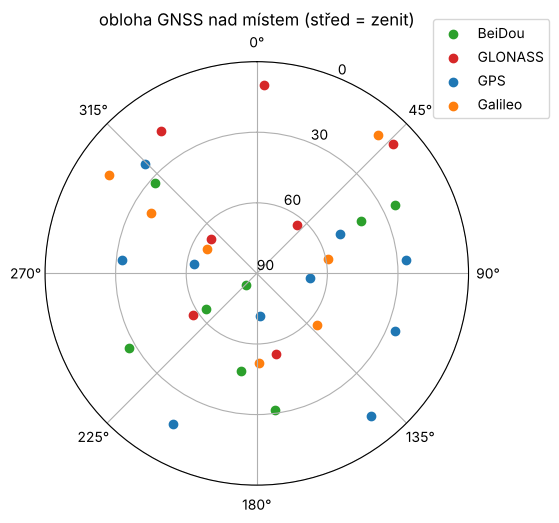

In [4]:
A, F = 6378137.0, 1 / 298.257223563
def ecef(lat, lon, h):
    la, lo = np.radians(lat), np.radians(lon); e2 = F * (2 - F); N = A / np.sqrt(1 - e2 * np.sin(la) ** 2)
    return np.array([(N + h) * np.cos(la) * np.cos(lo), (N + h) * np.cos(la) * np.sin(lo), (N * (1 - e2) + h) * np.sin(la)])

def az_el(t_utc, lat, lon, h=300.0):
    """Azimut a elevace (°) všech družic v čase t_utc pro místo lat, lon, h (elipsoidická výška)."""
    tg = gps_seconds(t_utc)
    la, lo = np.radians(lat), np.radians(lon)
    enu = np.array([[-np.sin(lo), np.cos(lo), 0],
                    [-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)],
                    [np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]])
    site = ecef(lat, lon, h)
    rows = []
    for sat in BY_SAT:
        p = sat_pos(sat, tg)
        if p is None: continue
        d = enu @ (p - site)
        rows.append((sat, SYSTEMS[sat[0]], np.degrees(np.arctan2(d[0], d[1])) % 360, np.degrees(np.arcsin(d[2] / np.linalg.norm(d)))))
    return pd.DataFrame(rows, columns=["družice", "systém", "az", "el"])

LAT, LON = 50.130, 14.373          # ◀ parametr: místo (kampus v Suchdole)
T0 = datetime(DAY.year, DAY.month, DAY.day, tzinfo=timezone.utc)
T_SKY = T0 + timedelta(hours=12)   # ◀ parametr: čas obrázku oblohy (UTC)
sky = az_el(T_SKY, LAT, LON)
mask = 10                          # ◀ parametr: elevační maska (°)
vis = sky[sky.el > mask]
print(f"{T_SKY:%Y-%m-%d %H:%M} UTC: nad maskou {mask}° je {len(vis)} družic:", vis.systém.value_counts().to_dict())
COL = {"GPS": "tab:blue", "Galileo": "tab:orange", "GLONASS": "tab:red", "BeiDou": "tab:green"}
fig = plt.figure(figsize=(5.5, 5.5)); ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_rlim(90, 0); ax.set_rticks([0, 30, 60, 90])
for s, g in vis.groupby("systém"):
    ax.scatter(np.radians(g.az), g.el, c=COL[s], label=s)
ax.legend(loc="lower left", bbox_to_anchor=(0.9, 0.85)); ax.set_title("obloha GNSS nad místem (střed = zenit)"); plt.show()

## 3. DOP během dne

DOP spočítáme z geometrie: každá družice dá řádek matice G s jednotkovým vektorem směru (východ, sever, nahoru) a jedničkou pro hodiny přijímače (každý systém má vlastní posun hodin). Q = (GᵀG)⁻¹, HDOP = √(Q_EE + Q_NN), VDOP = √Q_UU, PDOP = √(Q_EE + Q_NN + Q_UU).

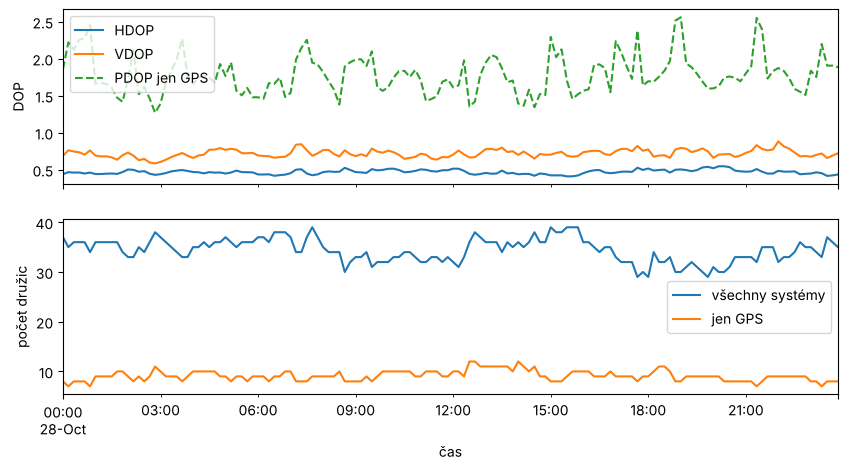

     HDOP  VDOP  PDOP  družic
min  0.41  0.58  0.73    29.0
50%  0.47  0.71  0.86    35.0
max  0.55  0.88  1.01    39.0


In [5]:
def dop(df, systems=("GPS", "Galileo", "GLONASS", "BeiDou")):
    df = df[df.systém.isin(systems)]
    if len(df) < 4 + df.systém.nunique() - 1:
        return np.nan, np.nan, np.nan, len(df)
    az, el = np.radians(df.az.values), np.radians(df.el.values)
    G = np.c_[-np.cos(el) * np.sin(az), -np.cos(el) * np.cos(az), -np.sin(el)]
    G = np.c_[G, pd.get_dummies(df.systém).values.astype(float)]
    Q = np.linalg.inv(G.T @ G)
    return np.sqrt(Q[0, 0] + Q[1, 1]), np.sqrt(Q[2, 2]), np.sqrt(Q[0, 0] + Q[1, 1] + Q[2, 2]), len(df)

def day_series(horizon=lambda az: np.full_like(az, mask, dtype=float), systems=("GPS", "Galileo", "GLONASS", "BeiDou"), lat=LAT, lon=LON, step=10):
    out = []
    for k in range(0, 24 * 60, step):
        tt = T0 + timedelta(minutes=k)
        s = az_el(tt, lat, lon)
        s = s[s.el > horizon(s.az.values)]
        out.append((tt, *dop(s, systems)))
    return pd.DataFrame(out, columns=["čas", "HDOP", "VDOP", "PDOP", "družic"]).set_index("čas")

open_sky = day_series()
gps_only = day_series(systems=("GPS",))
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
open_sky[["HDOP", "VDOP"]].plot(ax=ax[0]); gps_only[["PDOP"]].rename(columns={"PDOP": "PDOP jen GPS"}).plot(ax=ax[0], ls="--")
open_sky["družic"].plot(ax=ax[1], label="všechny systémy"); gps_only["družic"].plot(ax=ax[1], label="jen GPS"); ax[1].legend()
ax[0].set_ylabel("DOP"); ax[1].set_ylabel("počet družic"); plt.show()
print(open_sky.describe().loc[["min", "50%", "max"]].round(2))

> **✏️ Úkol 2.** Proč je VDOP po celý den větší než HDOP? Vysvětli to tím, kde družice na obloze jsou a kde být nemohou. Kolik družic vidí přijímač se čtyřmi systémy a kolik jen s GPS, a jak se to projeví na PDOP? Nastav masku 20° a pak 5°.

*Tvoje odpověď:* 

## 4. Les na jihu, nebo na severu?

Okraj lesa zakryje oblohu do výšky asi 35° na jedné straně. Dráhy GPS (sklon 55°) a Galilea (56°) nevystoupí nad 55–56° zeměpisné šířky, a proto ve střední Evropě zůstává na severní obloze ve středních výškách místo bez družic. Nízko nad severním obzorem ale vidíme družice, které letí „za pólem“. Která strana lesa vadí víc, proto není samozřejmé a záleží na výšce lesa.

In [6]:
forest_el = 35                         # ◀ parametr: výška okraje lesa nad obzorem (°)
south = lambda az: np.where((az > 90) & (az < 270), forest_el, mask)
north = lambda az: np.where((az < 90) | (az > 270), forest_el, mask)
res = pd.DataFrame({name: day_series(h, step=20).median() for name, h in [("volná obloha", lambda az: np.full_like(az, mask, float)), ("les na jihu", south), ("les na severu", north)]})
res.round(2)

,volná obloha,les na jihu,les na severu
HDOP,0.46,0.72,0.78
VDOP,0.71,1.03,1.19
PDOP,0.85,1.24,1.40
družic,35.00,27.00,24.00


> **✏️ Úkol 3.** Kde je na obloze z kroku 2 „díra“ bez družic a proč? Vyzkoušej forest_el 20°, 35° a 60°: vadí víc les na severu, nebo na jihu? Platí tedy častá rada „na severu je díra, takže les na severu nevadí“? Vysvětli výsledek podle toho, ve kterých výškách nad obzorem je na severu díra a ve kterých družice „za pólem“ (pomůže obrázek z kroku 2 v jiných hodinách, změň `T_SKY`). Kde bys postavil základnovou stanici nebo měřil vlícovací bod?

*Tvoje odpověď:* 

## 5. Hluboké údolí: skutečný horizont z DMR 5G

Pro bod u Vltavy v Roztokách spočítáme z modelu terénu výšku horizontu v každém azimutu a podle ní vybereme viditelné družice.

terén v bodě 183.1 m n. m.; horizont 0.3–12.6°


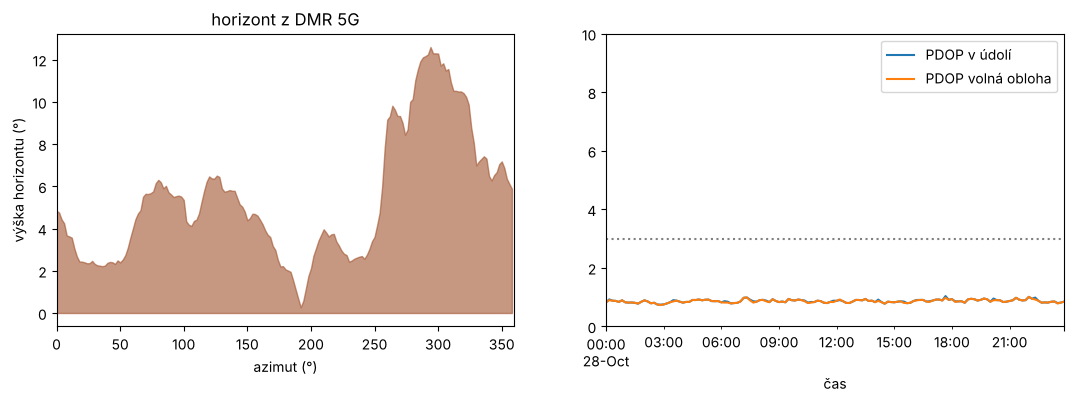

v údolí je PDOP < 3 a aspoň 10 družic 24.0 h z 24 h


In [7]:
VLAT, VLON = 50.1588, 14.3985        # ◀ parametr: bod v údolí (u Vltavy v Roztokách)
R_h = 2500
to_sjtsk = Transformer.from_crs(4326, 5514, always_xy=True)
vx, vy = to_sjtsk.transform(VLON, VLAT)
dem, tr = cuzk_raster("dmr5g", vx - R_h, vy - R_h, vx + R_h, vy + R_h, res=10)
row0, col0 = rasterio.transform.rowcol(tr, vx, vy); z0 = dem[row0, col0] + 1.8      # anténa 1,8 m nad terénem
azs = np.arange(0, 360, 2); dist = np.arange(20, R_h, 10)
hor = []
for a in np.radians(azs):
    xs, ys = vx + dist * np.sin(a), vy + dist * np.cos(a)
    rr, cc = rasterio.transform.rowcol(tr, xs, ys)
    hor.append(np.degrees(np.arctan2(dem[np.array(rr), np.array(cc)] - z0, dist)).max())
hor = np.maximum(np.array(hor), 0)
valley = lambda az: np.maximum(np.interp(az, azs, hor, period=360), mask)
print(f"terén v bodě {dem[row0, col0]:.1f} m n. m.; horizont {hor.min():.1f}–{hor.max():.1f}°")
v_day = day_series(valley, lat=VLAT, lon=VLON, step=10)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].fill_between(azs, 0, hor, color="sienna", alpha=0.6); ax[0].set(xlabel="azimut (°)", ylabel="výška horizontu (°)", xlim=(0, 360), title="horizont z DMR 5G")
v_day.PDOP.plot(ax=ax[1], label="PDOP v údolí"); open_sky.PDOP.plot(ax=ax[1], label="PDOP volná obloha"); ax[1].axhline(3, color="gray", ls=":")
ax[1].set_ylim(0, 10); ax[1].legend(); plt.show()
good = v_day[(v_day.PDOP < 3) & (v_day.družic >= 10)]
print(f"v údolí je PDOP < 3 a aspoň 10 družic {len(good) * 10 / 60:.1f} h z 24 h")

> **✏️ Úkol 4.** Které směry údolí zakrývá nejvíc a proč? Jak vysoko horizont sahá a je údolí z pohledu GNSS se čtyřmi systémy opravdu „hluboké“? Zkus `mask = 20` nebo bod pod skalní stěnou. Ve kterých hodinách vybraného dne (UTC) bys v údolí měřil vlícovací body? Proč model terénu nezachytí všechno, co signál ve skutečnosti blokuje nebo odráží (stromy, budovy, skalní stěny)?

*Tvoje odpověď:* 

## 6. Referenční stanice CZEPOS

Přesnost RTK klesá se vzdáleností od referenční stanice, protože se rozcházejí vlivy ionosféry, troposféry a drah. Výrobci obvykle udávají přesnost ve tvaru 1 cm + 1 ppm (1 mm na každý km).

In [8]:
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/0/query",
                 params={"where": "1=1", "outFields": "NAZEV_BODU,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
cz = pd.DataFrame([f["attributes"] for f in q["features"]])
cz["km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin(np.radians(cz.B - LAT) / 2) ** 2 + np.cos(np.radians(LAT)) * np.cos(np.radians(cz.B)) * np.sin(np.radians(cz.L - LON) / 2) ** 2))
cz["RTK horiz. (mm)"] = 10 + 1.0 * cz.km
print(f"stanic CZEPOS: {len(cz)}")
cz.sort_values("km").head(5).round(2)

stanic CZEPOS: 29


,NAZEV_BODU,B,L,HEL,NAZEV_KU,km,RTK horiz. (mm)
16,CPRG,50.13,14.46,356.02,Kobylisy,5.94,15.94
24,GOPE,49.91,14.79,592.60,Ondřejov u Prahy,38.05,48.05
18,CRAK,50.10,13.73,381.87,Rakovník,46.00,56.00
12,CLIT,50.54,14.14,243.28,Litoměřice,48.52,58.52
13,CMBO,50.41,14.91,303.46,Mladá Boleslav,49.24,59.24


## 7. Elipsoidická výška, nebo Bpv?

RTK dává výšku nad elipsoidem GRS80 (ETRS89). Mapy a projekty v Česku používají normální výšku v Bpv. Rozdíl je výšková anomálie ζ = h − H. Vezmeme zhušťovací body bodového pole v okolí, které mají obě výšky.

bodů: 45, ζ = 44.461 až 45.367 m, průměr 44.906 m


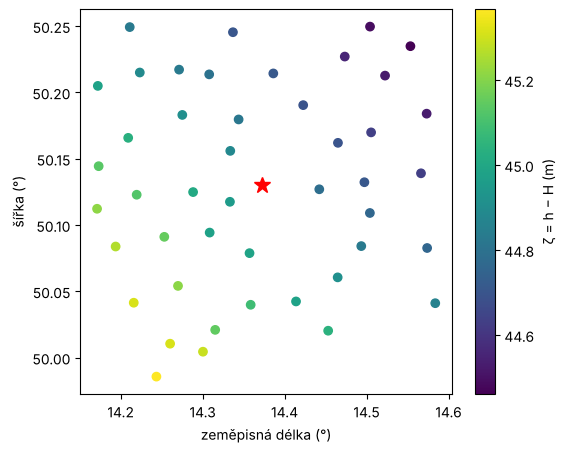

In [9]:
px, py = to_sjtsk.transform(LON, LAT)
half = 15000                       # ◀ parametr: poloviční šířka okolí (m)
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/2/query",
                 params={"geometry": f"{px - half},{py - half},{px + half},{py + half}", "geometryType": "esriGeometryEnvelope", "inSR": 5514,
                         "outFields": "CISLO_SMO5,CISLO,Y,X,VYSKA,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
pts = pd.DataFrame([f["attributes"] for f in q["features"]])
pts["H_Bpv"] = pd.to_numeric(pts.VYSKA, errors="coerce")
pts = pts.dropna(subset=["H_Bpv", "HEL"])
pts["zeta"] = pts.HEL - pts.H_Bpv
print(f"bodů: {len(pts)}, ζ = {pts.zeta.min():.3f} až {pts.zeta.max():.3f} m, průměr {pts.zeta.mean():.3f} m")
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(pts.L, pts.B, c=pts.zeta, cmap="viridis"); fig.colorbar(sc, label="ζ = h − H (m)")
ax.plot(LON, LAT, "r*", ms=12); ax.set(xlabel="zeměpisná délka (°)", ylabel="šířka (°)"); plt.show()

> **✏️ Úkol 5.** Jaká je výšková anomálie v okolí Suchdola a o kolik se mění na 30 km? Co se stane s modelem terénu nebo s vlícovacími body, když výšky z RTK zapíšeš jako Bpv bez převodu? Proč nestačí odečíst jednu konstantu pro celou republiku a co k převodu použít (model kvazigeoidu, transformační služba ČÚZK)? Jak daleko je nejbližší stanice CZEPOS a jak velkou chybu RTK z toho čekáš?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Vysílané efemeridy: International GNSS Service (IGS), denní sloučený soubor navigačních zpráv BRDC00IGS_R, archiv BKG https://igs.bkg.bund.de/root_ftp/IGS/BRDC/ (data IGS jsou volně dostupná, s uvedením zdroje). Johnston, G., Riddell, A., Hausler, G. (2017). The International GNSS Service. In *Springer Handbook of Global Navigation Satellite Systems*, 967–982.
- Výpočet polohy družic: IS-GPS-200 (rozhraní GPS, kap. 20.3.3.4.3), Galileo OS SIS ICD, BeiDou ICD B1I (geostacionární družice), GLONASS ICD (integrace pohybu, příloha J); formát RINEX 3.05 (IGS/RTCM).
- Bodová pole a stanice CZEPOS: © ČÚZK, služba https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer (CC BY 4.0).
- DMR 5G: © ČÚZK, CC BY 4.0, https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer
- Hofmann-Wellenhof, B., Lichtenegger, H., Wasle, E. (2008). *GNSS – Global Navigation Satellite Systems*. Springer (DOP, víc systémů, RTK).

### Jak citovat

OpenSkyLab (2026). GNSS pod oblohou: skutečné družice, DOP, terén a výška v Bpv [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/gnss_sky_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*